::: {.case-links}
[<i class="bi bi-journal-text"></i> Appendix](01_reproduce_official_results.ipynb){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-sliders"></i> Explorer](../explorer/reward.qmd){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-github"></i> Code](https://github.com/matheusmmmp/digilab-reward-case-study){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-table"></i> Data](../data/SCHEMA.md){.btn .btn-outline-secondary .btn-sm}
[<i class="bi bi-quote"></i> Cite](../index.qmd#cite){.btn .btn-outline-secondary .btn-sm}
:::

**In short.** A virtual pet sleeps a lot. I asked whether petting it right after it eats or plays (and giving its learning agent reward credit for that moment) would keep it awake more. Before running anything I wrote down the design, the outcome, the analysis and the rule that turns numbers into an answer. Then I ran it once: 9,600 simulated lives. The answer, read by the pre-written rule, was **no: with the reward the pet sleeps more**, slightly. Its welfare measure improved, but that gain cannot be told apart from what petting does to the body: it is not evidence that the reward credit itself makes the pet better off. The analysis crashed after the lives were saved; this page also shows that bug, how it was fixed before any result was read, and what I would do differently.

Every official number on this page is recomputed in a code cell from the published data (`data/lives.parquet`) and asserted against the official values (`data/reference.json`) to within 1e-9. Anything that was *not* part of the official, pre-registered result is marked **Exploratory, after the result**. Code is folded; click "Code" to see it.

In [1]:
#| label: setup
#| code-summary: "Setup: imports, data, shared helpers"
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

import casestudy as cs
from casestudy import style

style.apply()
REF = cs.REF
CHECKS = []  # every official number shown below is asserted and logged here


def check(got, ref, what):
    cs.assert_matches(got, ref, what)
    CHECKS.append(what)


def say(text):
    display(Markdown(text))


def show(df):
    # plain HTML table without the index: deterministic markup, unlike a Styler
    display(HTML(df.to_html(index=False, border=0, classes="table table-sm")))

## 1. The question

The pet is a small simulated animal driven by **a learning agent: when it receives reward credit, the action it just took becomes more likely**. Its day is a long sequence of decisions (eat, play, sleep and so on), and in the simulation it sleeps a lot.

The question, in plain words: **if its simulated owner pets it right after it eats or plays, does the pet stay awake more?** Petting does two things at once: it changes the pet's body state, and it can give the learning agent reward credit for what it just did. A careful answer has to separate those two.

Before the run I also wrote down what I expected: *"no: it sleeps more or stays the same"*. That expectation came from a quick look at 20 units run with the seeds reserved for the project's software tests ("test seeds"), which are not part of the research data.

## 2. Why pre-register

With a simulator you can run as many variants as you like and report the one that looks best. To make that impossible, the question, outcome, analysis, relevant effect size and reading rule were committed to the project's history *before* the simulation code was merged and long before the run. The pre-registration entry is commit `455c6d61` of the project's private repository, dated 2026-11-20 14:06:26 UTC−3; its relevant lines are quoted, translated and in the original Portuguese, in the [appendix](#appendix-the-pre-registration-entry), and [PROVENANCE](../PROVENANCE.md) lists every hash and file checksum. The commit times (2026-11-20, UTC−3) tell the story:

In [2]:
#| label: timeline
#| code-summary: "Timeline from the commit history"
timeline = pd.DataFrame([
    ("14:06", "Pre-registration entry committed", "before"),
    ("14:19", "Analysis plan approved", "before"),
    ("15:13", "Simulation code merged", "before"),
    ("15:51", "Run started", "run"),
    ("18:36", "All 9,600 lives measured and saved; analysis crashed", "run"),
    ("18:38", "Fix committed (no result number had been read)", "after"),
    ("18:41", "Re-analysis of the saved measurements", "after"),
    ("18:44", "Result written", "after"),
], columns=["time (UTC−3)", "event", "phase"])
t = pd.to_datetime(timeline["time (UTC−3)"], format="%H:%M")
run_hours = (t[4] - t[3]).total_seconds() / 3600
fix_minutes = (t[5] - t[4]).total_seconds() / 60
show(timeline)
say(f"The run took **{int(run_hours)} h {round(run_hours % 1 * 60)} min** of wall time, inside the pre-registered stopping rule "
    f"(projected cost above 4 h → no run). The fix was committed **{fix_minutes:.0f} min** after the lives were saved.")

time (UTC−3),event,phase
14:06,Pre-registration entry committed,before
14:19,Analysis plan approved,before
15:13,Simulation code merged,before
15:51,Run started,run
18:36,"All 9,600 lives measured and saved; analysis crashed",run
18:38,Fix committed (no result number had been read),after
18:41,Re-analysis of the saved measurements,after
18:44,Result written,after


The run took **2 h 45 min** of wall time, inside the pre-registered stopping rule (projected cost above 4 h → no run). The fix was committed **2 min** after the lives were saved.

The stopping rule was simple: run once; integrity checks fail loudly before any measurement; if the projected cost is above 4 hours, do not run.

## 3. The design

Four **arms** (what happens around eating and playing) × four simulated **owner types** × three **places** of the food × 200 **paired units**. A unit uses the same random seed in all four arms, so every comparison between arms is a paired one. Each life lasts 14 simulated days.

In [3]:
#| label: design
#| code-summary: "Arms and contrasts"
arms = pd.DataFrame([
    ("no_petting", "control: no extra petting", "no", "—"),
    ("petting_body_only", "extra petting changes the pet's body state", "no", "—"),
    ("petting_with_credit", "extra petting plus reward credit", "yes", "right after eating/playing"),
    ("petting_with_credit_random_time", "the same number of extra petting acts with credit", "yes", "at a random time"),
], columns=["arm", "what happens", "reward credit", "timing"])
contrasts = pd.DataFrame([
    ("D1", "with_credit − no_petting", "the whole effect (primary)"),
    ("D2", "with_credit − random_time", "the timing"),
    ("D3", "with_credit − body_only", "the credit"),
], columns=["contrast", "difference", "what it isolates"])
assert list(arms.arm) == cs.ARMS
for cid, (a, b) in zip(["D1", "D2", "D3"], [("petting_with_credit", "no_petting"),
                                           ("petting_with_credit", "petting_with_credit_random_time"),
                                           ("petting_with_credit", "petting_body_only")]):
    assert cs.CONTRASTS[cid] == {"a": a, "b": b}
show(arms)
show(contrasts)

arm,what happens,reward credit,timing
no_petting,control: no extra petting,no,—
petting_body_only,extra petting changes the pet's body state,no,—
petting_with_credit,extra petting plus reward credit,yes,right after eating/playing
petting_with_credit_random_time,the same number of extra petting acts with credit,yes,at a random time


contrast,difference,what it isolates
D1,with_credit − no_petting,the whole effect (primary)
D2,with_credit − random_time,the timing
D3,with_credit − body_only,the credit


Owner types: `attentive`, `neglectful`, `random`, `inconsistent`. Places of the food: `at_feeder`, `near`, `far`. The 4 × 3 owner/place combinations are the 12 **cells**.

**Primary outcome.** `awake_frac_d1_14`: the fraction of the pet's decisions over the 14 days that were not "sleep". Each life has 1,344 decisions (96 a day, one every 15 simulated minutes), so a fraction of decisions reads directly as a fraction of the pet's day. The project's primary welfare measure, `time_well` (fraction of decisions taken while the pet was neither deprived nor exhausted), is read alongside it.

**Analysis.** For each unit, take the arm difference in each of the 12 cells and average them: one number per unit. The estimate is the mean of the 200 unit numbers; the 95% confidence interval is Student t over the units.

**Relevant size.** δ_A = 0.02 of the day awake. The plan marks it as having **no external source**: it is a judgement call, written down before the run but after the 20-unit look at test seeds mentioned above. The same holds for the welfare margin (0.032) and for the premise floors: the pre-registered minimums the design had to reach for a reading to hold (for example, at least 50 extra petting events per life in 95% of the lives). A premise that misses its floor is recorded and limits what can be read; it does not stop the run.

**Reading rules, applied in order** (the first line that applies wins):

| rule | condition | answer |
|---|---|---|
| L-AWAKE (D1, awake fraction) | CI upper < 0 | no: with the reward the pet sleeps more |
| | CI within ±δ_A | no: stays the same (if the lower bound is also above 0: "goes up, but below the relevant size") |
| | CI lower > δ_A | yes, stays awake more |
| | otherwise | inconclusive |
| L-WELL (D1, time_well) | CI lower > 0 | the pet is better off |
| | CI lower > −0.032 | not worse |
| | CI upper < −0.032 | worse |
| | otherwise | inconclusive |
| L-WHY (only if L-AWAKE is not "stays the same") | D2 and D3 lower bounds > 0 | by the timely reward and by what the pet learns |
| | only D3 lower bound > 0 | by the credit, at any time |
| | neither | by the body effect of petting, not by learning |
| | the dose premise failed (too few credits had an effect) | only the third answer can come out |

In [4]:
#| label: delta-minutes
assert cs.DECISIONS_PER_DAY * 15 == cs.MIN_PER_DAY  # one decision every 15 simulated minutes
say(f"For scale: δ_A = {cs.DELTA_A} of the decisions ({cs.DECISIONS_PER_DAY} decisions a day, one every 15 minutes), "
    "read as a share of a 24-hour day, is about "
    f"**{cs.minutes(cs.DELTA_A):.0f} minutes** of the pet's day.")

For scale: δ_A = 0.02 of the decisions (96 decisions a day, one every 15 minutes), read as a share of a 24-hour day, is about **29 minutes** of the pet's day.

## 4. The data

One row per simulated life, 13 columns; the full dictionary is on the [data schema](../data/SCHEMA.md) page. Only outcome measures are published; the agent's internal state is not. The checks below are plain DuckDB SQL over the parquet file (the same checks run in `scripts/check_data.py` before anything else).

In [5]:
#| label: data-counts
#| code-summary: "DuckDB: counts and pairing"
per_arm = cs.sql("SELECT arm, count(*) AS lives, count(DISTINCT owner || place) AS cells, "
                 "count(DISTINCT unit) AS units FROM lives GROUP BY arm ORDER BY arm")
show(per_arm)
pairing = cs.sql("""
    SELECT count(*) AS unit_cells, min(arms) AS min_arms, max(arms) AS max_arms
    FROM (SELECT unit, owner, place, count(DISTINCT arm) AS arms FROM lives GROUP BY ALL)""")
show(pairing)
n_lives = int(per_arm.lives.sum())
assert n_lives == REF["preregistered"]["lives"] == 9600
assert (per_arm.cells == 12).all() and (per_arm.units == cs.N_UNITS).all()
assert pairing.min_arms[0] == pairing.max_arms[0] == 4
say(f"**{n_lives:,} lives** = {len(per_arm)} arms × {per_arm.cells[0]} cells × {per_arm.units[0]} units; "
    f"each of the {pairing.unit_cells[0]:,} unit-cells appears in all {pairing.max_arms[0]} arms.")

arm,lives,cells,units
no_petting,2400,12,200
petting_body_only,2400,12,200
petting_with_credit,2400,12,200
petting_with_credit_random_time,2400,12,200


unit_cells,min_arms,max_arms
2400,4,4


**9,600 lives** = 4 arms × 12 cells × 200 units; each of the 2,400 unit-cells appears in all 4 arms.

In [6]:
#| label: arm-means
#| code-summary: "DuckDB: arm means, checked against the official values"
means = cs.sql("SELECT arm, avg(awake_frac_d1_14) AS awake_frac_d1_14, avg(time_well) AS time_well "
               "FROM lives GROUP BY arm ORDER BY arm")
for r in means.itertuples():
    for m in ("awake_frac_d1_14", "time_well"):
        assert abs(getattr(r, m) - REF["arm_means"][r.arm][m]) <= cs.TOL
        CHECKS.append(f"arm mean {r.arm} {m}")
display(means.set_index("arm").round(4))

,awake_frac_d1_14,time_well
arm,,
no_petting,0.5300,0.7767
petting_body_only,0.5121,0.7939
petting_with_credit,0.5191,0.7951
petting_with_credit_random_time,0.5095,0.7926


## 5. The result

### The contrasts

The official paired contrasts, recomputed from the parquet and asserted against `reference.json`:

In [7]:
#| label: contrasts
#| code-summary: "Recompute D1, D2, D3 and assert them"
res = {}
for m in ("awake_frac_d1_14", "time_well"):
    for cid in ("D1", "D2", "D3"):
        r = cs.contrast(cid, m)
        check(r, REF["contrasts"][m][cid], f"{cid} {m}")
        res[(m, cid)] = r
table = pd.DataFrame([dict(measure=m, contrast=c, estimate=r["mean"], ci_low=r["ci_low"],
                           ci_high=r["ci_high"]) for (m, c), r in res.items()])
show(table.round(4))

measure,contrast,estimate,ci_low,ci_high
awake_frac_d1_14,D1,-0.0109,-0.0113,-0.0105
awake_frac_d1_14,D2,0.0096,0.0093,0.0100
awake_frac_d1_14,D3,0.0070,0.0067,0.0073
time_well,D1,0.0183,0.0152,0.0215
time_well,D2,0.0025,-0.0007,0.0056
time_well,D3,0.0012,-0.0015,0.0038


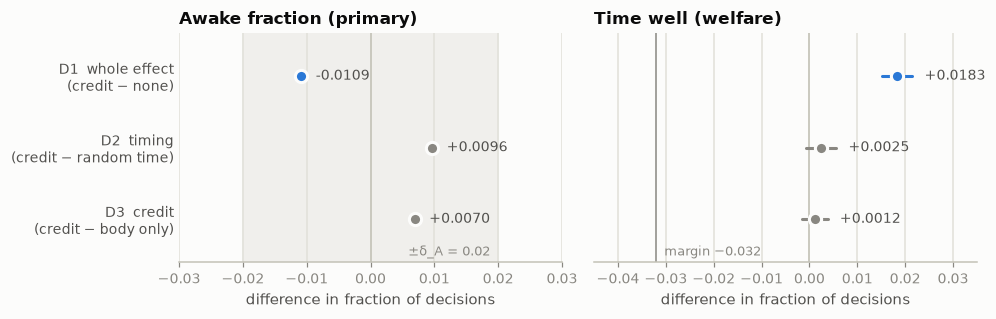

In [8]:
#| label: fig-forest
#| fig-cap: "The three pre-registered contrasts with 95% CIs (on the awake fraction the intervals are narrower than the dots). Left: awake fraction, with the pre-registered 'stays the same' band ±δ_A. Right: time well, with the non-inferiority margin −0.032."
#| code-summary: "Forest plot"
#| fig-alt: "Two-panel forest plot of the three pre-registered contrasts. Left, awake fraction: D1 (credit minus none) is -0.0109, below zero, while D2 (timing, +0.0096) and D3 (credit, +0.0070) are above zero; all three lie inside the ±δ_A band. Right, time well: D1 is +0.0183 with its interval above zero, while the intervals of D2 and D3 include zero; all three lie above the -0.032 margin."
labels = {"D1": "D1  whole effect\n(credit − none)", "D2": "D2  timing\n(credit − random time)",
          "D3": "D3  credit\n(credit − body only)"}
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.0), sharey=True)
for ax, m, title in zip(axes, ("awake_frac_d1_14", "time_well"),
                        ("Awake fraction (primary)", "Time well (welfare)")):
    for i, cid in enumerate(("D1", "D2", "D3")):
        r = res[(m, cid)]
        color = style.ACCENT if cid == "D1" else style.CONTEXT
        ax.plot([r["ci_low"], r["ci_high"]], [i, i], color=color, lw=2, zorder=3)
        ax.plot(r["mean"], i, "o", ms=8, color=color, mec=style.SURFACE, mew=2, zorder=4)
        ax.annotate(f"{r['mean']:+.4f}", (r["ci_high"], i), xytext=(8, 0), textcoords="offset points",
                    va="center", color=style.INK_2, fontsize=9)
    ax.axvline(0, color=style.BASELINE, lw=1, zorder=1)
    ax.set_title(title)
    ax.set_ylim(2.6, -0.6)
    ax.grid(axis="y", visible=False)
axes[0].axvspan(-cs.DELTA_A, cs.DELTA_A, color=style.WASH, zorder=0)
axes[0].text(cs.DELTA_A, 2.55, f"±δ_A = {cs.DELTA_A}  ", ha="right", va="bottom", color=style.MUTED, fontsize=8.5)
axes[0].set_xlim(-0.03, 0.03)
axes[1].axvline(-cs.MARGIN_WELL, color=style.MUTED, lw=1, zorder=1)
axes[1].text(-cs.MARGIN_WELL, 2.55, f"  margin −{cs.MARGIN_WELL}", ha="left", va="bottom", color=style.MUTED, fontsize=8.5)
axes[1].set_xlim(-0.045, 0.035)
axes[0].set_yticks(range(3), [labels[c] for c in ("D1", "D2", "D3")])
for ax in axes:
    ax.set_xlabel("difference in fraction of decisions")
fig.tight_layout()
plt.show()

### Applying the rules

The reading rules are code (in `casestudy/__init__.py`), applied to the recomputed intervals; the label they return is asserted against the label recorded in the official result.

In [9]:
#| label: readings
#| code-summary: "Apply L-AWAKE, L-WELL and L-WHY"
a, w = res[("awake_frac_d1_14", "D1")], res[("time_well", "D1")]
d2, d3 = res[("awake_frac_d1_14", "D2")], res[("awake_frac_d1_14", "D3")]
w2, w3 = res[("time_well", "D2")], res[("time_well", "D3")]
l_awake = cs.read_awake(a["ci_low"], a["ci_high"])
l_well = cs.read_well(w["ci_low"], w["ci_high"])
l_why = cs.read_why(l_awake, d2["ci_low"], d3["ci_low"], REF["dose_premise_held"])
for rule, label in (("L-AWAKE", l_awake), ("L-WELL", l_well), ("L-WHY", l_why)):
    assert label == REF["readings"][rule]["label"], (rule, label)
    CHECKS.append(f"reading {rule}")
within = -cs.DELTA_A <= a["ci_low"] and a["ci_high"] <= cs.DELTA_A
assert within
assert all(r["ci_low"] < 0 < r["ci_high"] for r in (w2, w3))  # the time-well caveat below relies on this
say(f"""
- **L-AWAKE: "{l_awake}".** D1 on the awake fraction is {cs.fmt(a)}: the whole interval is below zero.
  That is about **{abs(cs.minutes(a['mean'])):.0f} minutes less awake per simulated day**.
  The interval also fits inside ±δ_A, so the "stays the same" line would apply too; the rule is read
  in order and the first line ("upper < 0") applies.
- **L-WELL: "{l_well}".** D1 on time well is {cs.fmt(w)}: the lower bound is above zero.
  **This gain cannot be separated from the body effect of petting:** on time well, D2 is {cs.fmt(w2)} and
  D3 is {cs.fmt(w3)}, both intervals include zero. The three arms with petting sit close to each other,
  above no_petting, so the welfare gain is not shown to come from the reward credit or its timing.
- **L-WHY.** D2's lower bound ({d2['ci_low']:+.4f}) and D3's ({d3['ci_low']:+.4f}) are both above zero, so the
  rule returns **"{l_why}"**. Read it with the caveat just below: D1 has the opposite sign.
""")


- **L-AWAKE: "no: with the reward the pet sleeps more".** D1 on the awake fraction is -0.0109 [-0.0113; -0.0105]: the whole interval is below zero.
  That is about **16 minutes less awake per simulated day**.
  The interval also fits inside ±δ_A, so the "stays the same" line would apply too; the rule is read
  in order and the first line ("upper < 0") applies.
- **L-WELL: "the pet is better off".** D1 on time well is +0.0183 [+0.0152; +0.0215]: the lower bound is above zero.
  **This gain cannot be separated from the body effect of petting:** on time well, D2 is +0.0025 [-0.0007; +0.0056] and
  D3 is +0.0012 [-0.0015; +0.0038], both intervals include zero. The three arms with petting sit close to each other,
  above no_petting, so the welfare gain is not shown to come from the reward credit or its timing.
- **L-WHY.** D2's lower bound (+0.0093) and D3's (+0.0067) are both above zero, so the
  rule returns **"by the timely reward and by what the pet learns"**. Read it with the caveat just below: D1 has the opposite sign.


In [10]:
#| label: why-signs
signs = {c: np.sign(res[("awake_frac_d1_14", c)]["mean"]) for c in ("D1", "D2", "D3")}
assert signs == {"D1": -1, "D2": 1, "D3": 1}
say(f"""**The L-WHY label needs a caveat.** It was written assuming D1 would have the same sign as D2 and D3.
It came out opposite: D1 is negative ({a['mean']:+.4f}) while D2 ({d2['mean']:+.4f}) and D3 ({d3['mean']:+.4f})
are positive. The official result keeps the label as written and states what the numbers actually show:
**petting's effect on the body makes the pet sleep more; the credit (D3) and the right timing (D2) push it
back toward awake, without covering the loss.**""")
ep, late = cs.contrast("D1", "episode_rate"), cs.contrast("D1", "awake_frac_d8_14")
check(ep, REF["contrasts"]["episode_rate"]["D1"], "guard D1 episode_rate")
check(late, REF["contrasts"]["awake_frac_d8_14"]["D1"], "window D1 awake_frac_d8_14")
say(f"""Two more official numbers, one line each. **Guard:** the share of hunger episodes closed by eating
rises, D1 = {cs.fmt(ep)}; the plan gives this guard no automatic verdict. **Days 8–14 only:** D1 on the
awake fraction shrinks to {cs.fmt(late)}.""")

**The L-WHY label needs a caveat.** It was written assuming D1 would have the same sign as D2 and D3.
It came out opposite: D1 is negative (-0.0109) while D2 (+0.0096) and D3 (+0.0070)
are positive. The official result keeps the label as written and states what the numbers actually show:
**petting's effect on the body makes the pet sleep more; the credit (D3) and the right timing (D2) push it
back toward awake, without covering the loss.**

Two more official numbers, one line each. **Guard:** the share of hunger episodes closed by eating
rises, D1 = +0.0209 [+0.0147; +0.0270]; the plan gives this guard no automatic verdict. **Days 8–14 only:** D1 on the
awake fraction shrinks to -0.0062 [-0.0069; -0.0056].

### Absolute and standardized size (Exploratory, after the result)

The standardized effect dz (mean of the unit differences divided by their standard deviation) was not part of the official reading.

In [11]:
#| label: dz
dz = pd.DataFrame([dict(measure=m, contrast=c, estimate=r["mean"], sd_of_unit_diffs=r["sd"], dz=r["dz"],
                        minutes_per_day=f"{cs.minutes(r['mean']):+.1f}" if m == "awake_frac_d1_14" else "—")
                   for (m, c), r in res.items()])
show(dz.round({"estimate": 4, "sd_of_unit_diffs": 4, "dz": 2}))
assert abs(a["mean"]) < cs.DELTA_A and abs(a["dz"]) > 0.8
say(f"""D1 on the awake fraction has dz = {a['dz']:.2f}, which looks enormous next to the usual
"0.8 is large" conventions. Yet it is about {abs(cs.minutes(a['mean'])):.0f} minutes a day, under the
pre-registered δ_A. The two are consistent: each unit number is an average over 12 cells, and the arms share
the same seed, so most noise cancels and the standard deviation of the unit differences is tiny
({a['sd']:.4f}). A standardized effect measures how *reliably* the difference shows up, not how *much*
it matters; that is why both are reported here, with the absolute one first.""")

measure,contrast,estimate,sd_of_unit_diffs,dz,minutes_per_day
awake_frac_d1_14,D1,-0.0109,0.0030,-3.70,-15.7
awake_frac_d1_14,D2,0.0096,0.0027,3.55,+13.9
awake_frac_d1_14,D3,0.0070,0.0022,3.18,+10.0
time_well,D1,0.0183,0.0226,0.81,—
time_well,D2,0.0025,0.0225,0.11,—
time_well,D3,0.0012,0.0188,0.06,—


D1 on the awake fraction has dz = -3.70, which looks enormous next to the usual
"0.8 is large" conventions. Yet it is about 16 minutes a day, under the
pre-registered δ_A. The two are consistent: each unit number is an average over 12 cells, and the arms share
the same seed, so most noise cancels and the standard deviation of the unit differences is tiny
(0.0030). A standardized effect measures how *reliably* the difference shows up, not how *much*
it matters; that is why both are reported here, with the absolute one first.

## 6. Where it happens (descriptive)

The official result also reports the contrasts by owner type (averaging the 3 places within each unit) and by place (averaging the 4 owners). These breakdowns are **descriptive**: no reading rule applies to them. They are recomputed here and asserted against the official breakdowns.

In [12]:
#| label: breakdowns
#| code-summary: "Recompute the by-owner and by-place contrasts and assert them"
rows = []
for by, groups, key in (("owner", cs.OWNERS, "by_owner"), ("place", cs.PLACES, "by_place")):
    for g in groups:
        for m in ("awake_frac_d1_14", "time_well"):
            for cid in ("D1", "D2", "D3"):
                r = cs.contrast(cid, m, f"{by} = '{g}'")
                check(r, REF[key][g][m][cid], f"{key} {g} {cid} {m}")
                rows.append(dict(by=by, group=g, measure=m, contrast=cid, **r))
br = pd.DataFrame(rows)
wide = br.assign(value=[cs.fmt(r, 4) for r in rows]).pivot_table(
    index=["by", "group"], columns=["measure", "contrast"], values="value", aggfunc="first", sort=False)
display(wide)

measure                       awake_frac_d1_14                              \
contrast                                    D1                          D2   
by    group                                                                  
owner attentive     -0.0142 [-0.0150; -0.0134]  +0.0149 [+0.0142; +0.0156]   
      neglectful    -0.0098 [-0.0104; -0.0093]  +0.0042 [+0.0036; +0.0047]   
      random        -0.0055 [-0.0061; -0.0049]  +0.0046 [+0.0040; +0.0052]   
      inconsistent  -0.0141 [-0.0151; -0.0132]  +0.0148 [+0.0142; +0.0155]   
place at_feeder     -0.0091 [-0.0099; -0.0084]  +0.0106 [+0.0099; +0.0113]   
      near          -0.0078 [-0.0083; -0.0073]  +0.0110 [+0.0106; +0.0114]   
      far           -0.0158 [-0.0166; -0.0150]  +0.0073 [+0.0067; +0.0080]   

measure                                                          time_well  \
contrast                                    D3                          D1   
by    group                                                                  
owner attentive     +0.0126 [+0.0120; +0.0132]  +0.0252 [+0.0166; +0.0337]   
      neglectful    +0.0010 [+0.0006; +0.0015]  +0.0118 [+0.0079; +0.0158]   
      random        +0.0014 [+0.0009; +0.0019]  +0.0036 [+0.0005; +0.0068]   
      inconsistent  +0.0128 [+0.0122; +0.0134]  +0.0327 [+0.0254; +0.0400]   
place at_feeder     +0.0091 [+0.0085; +0.0097]  -0.0032 [-0.0057; -0.0006]   
      near          +0.0088 [+0.0084; +0.0091]  -0.0016 [-0.0025; -0.0007]   
      far           +0.0030 [+0.0024; +0.0036]  +0.0598 [+0.0506; +0.0690]   

measure                                                                     
contrast                                    D2                          D3  
by    group                                                                 
owner attentive     -0.0032 [-0.0116; +0.0051]  -0.0033 [-0.0103; +0.0038]  
      neglectful    +0.0089 [+0.0051; +0.0127]  +0.0097 [+0.0061; +0.0134]  
      random        -0.0020 [-0.0052; +0.0011]  -0.0019 [-0.0047; +0.0009]  
      inconsistent  +0.0062 [-0.0016; +0.0140]  +0.0001 [-0.0067; +0.0069]  
place at_feeder     -0.0070 [-0.0098; -0.0041]  -0.0061 [-0.0086; -0.0035]  
      near          -0.0041 [-0.0051; -0.0032]  -0.0025 [-0.0035; -0.0016]  
      far           +0.0185 [+0.0095; +0.0275]  +0.0121 [+0.0047; +0.0195]

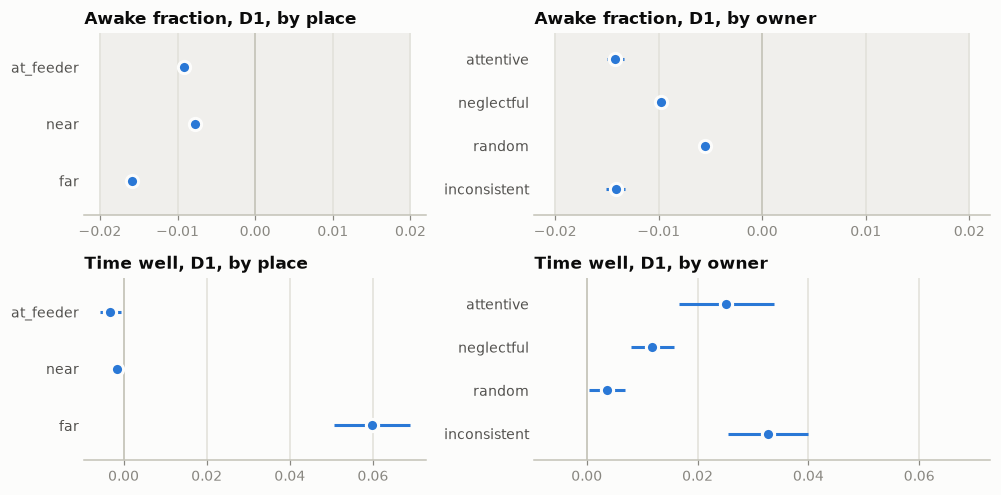

In [13]:
#| label: fig-breakdown
#| fig-cap: "D1 (credit − none) by place and by owner type, with 95% CIs. Descriptive: no reading rule applies to subgroups."
#| code-summary: "Breakdown chart"
#| fig-alt: "Four-panel chart of D1 (credit minus none) with 95% intervals, by place and by owner type. On the awake fraction every group is below zero, most in the far place (-0.0158) and least with the random owner (-0.0055). On time well the gain sits in the far place (+0.0598), with small drops at_feeder and near; by owner all four groups are above zero, largest with the inconsistent (+0.0327) and attentive (+0.0252) owners."
fig, axes = plt.subplots(2, 2, figsize=(9.2, 4.6), sharex="row",
                         gridspec_kw={"width_ratios": [3, 4]})
for i, (m, title) in enumerate((("awake_frac_d1_14", "Awake fraction, D1"), ("time_well", "Time well, D1"))):
    for j, (by, groups) in enumerate((("place", cs.PLACES), ("owner", cs.OWNERS))):
        ax = axes[i, j]
        sub = br[(br.by == by) & (br.measure == m) & (br.contrast == "D1")].set_index("group").loc[groups]
        y = np.arange(len(groups))
        ax.hlines(y, sub.ci_low, sub.ci_high, color=style.ACCENT, lw=2, zorder=3)
        ax.plot(sub["mean"], y, "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=4)
        ax.axvline(0, color=style.BASELINE, lw=1, zorder=1)
        if m == "awake_frac_d1_14":
            ax.axvspan(-cs.DELTA_A, cs.DELTA_A, color=style.WASH, zorder=0)
        ax.set_yticks(y, groups)
        ax.set_ylim(len(groups) - 0.4, -0.6)
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{title}, by {by}")
fig.tight_layout()
plt.show()

In [14]:
#| label: by-place-text
pl_ = br[(br.by == "place") & (br.measure == "time_well") & (br.contrast == "D1")].set_index("group")
drops = pl_.loc[["at_feeder", "near"]]
assert pl_.loc["far", "ci_low"] > 0 and (drops.ci_high < 0).all() and (drops.ci_low > -cs.MARGIN_WELL).all()
say("On time well, the whole D1 gain sits in the `far` place "
    f"({cs.fmt(pl_.loc['far'])}). In `at_feeder` ({cs.fmt(pl_.loc['at_feeder'])}) and "
    f"`near` ({cs.fmt(pl_.loc['near'])}) time well drops: both intervals exclude zero, and both drops are "
    f"within the pre-registered margin of {cs.MARGIN_WELL}. "
    "This is descriptive: the plan did not set a rule for places.")

On time well, the whole D1 gain sits in the `far` place (+0.0598 [+0.0506; +0.0690]). In `at_feeder` (-0.0032 [-0.0057; -0.0006]) and `near` (-0.0016 [-0.0025; -0.0007]) time well drops: both intervals exclude zero, and both drops are within the pre-registered margin of 0.032. This is descriptive: the plan did not set a rule for places.

## 7. The bug and the fix

**What happened.** All lives had been simulated, measured and saved when the analysis stopped with

```
KeyError: 'saude_media'
```

One pre-registered **guard metric** (the pet's health over days 8–14) had never been recorded per life. The smoke test before the run exercised the simulation but **not the analysis step**, so the missing field only showed up at the end.

**The fix** (committed 2 minutes after the lives were saved, before any result number was read):

1. The guard was removed from the list of measured outcomes and is reported as **NOT MEASURED**, rather than silently dropped.
2. A re-analysis mode (`--reanalisar`) reads the saved measurements and **refuses to run** if the number of lives or logs differs from the plan.
3. **No life was re-run and no reading rule changed.** Measuring the guard after the fact would have meant replaying the 9,600 logs (about 1 hour, estimated); it was not done.

In [15]:
#| label: bug-facts
assert REF["guards_not_measured"] == 1
say(f"Guards reported as not measured in the official result: **{REF['guards_not_measured']}**. "
    f"Lives analysed after the fix: **{n_lives:,}**, the planned number, which is what the "
    "`--reanalisar` mode checks before reading anything.")

Guards reported as not measured in the official result: **1**. Lives analysed after the fix: **9,600**, the planned number, which is what the `--reanalisar` mode checks before reading anything.

**Why this matters.** The result itself was not touched: same lives, same contrasts, same rules. But one safety question that was planned (*does this make the pet less healthy?*) has no answer. The honest report is that the guard is missing, not that it passed.

## 8. Exploratory, after the result

Nothing in this section was in the plan. It does not change or replace the official readings above.

### (a) The body effect alone: body_only − no_petting

L-WHY's caveat says the body effect of petting pushes toward sleep. The plan had no contrast for that; here is its paired interval, computed the same way as D1–D3.

In [16]:
#| label: body-only
#| code-summary: "Paired CI for petting_body_only − no_petting"
body = cs.summarize(cs.paired_differences("petting_body_only", "no_petting", "awake_frac_d1_14"))
arm_diff = REF["arm_means"]["petting_body_only"]["awake_frac_d1_14"] - REF["arm_means"]["no_petting"]["awake_frac_d1_14"]
assert abs(body["mean"] - arm_diff) <= cs.TOL  # balanced pairing: mean of differences = difference of means
say(f"**Exploratory, after the result.** petting_body_only − no_petting on the awake fraction: "
    f"**{cs.fmt(body)}** (about {abs(cs.minutes(body['mean'])):.0f} minutes less awake per day). "
    f"Petting that only acts on the body makes the pet sleep more, by more than the whole D1 "
    f"({a['mean']:+.4f}); the credit wins part of it back (D3 {d3['mean']:+.4f}). "
    "Caveat: arms diverge after the first petting, so this split between body and credit is not perfect.")

**Exploratory, after the result.** petting_body_only − no_petting on the awake fraction: **-0.0179 [-0.0183; -0.0175]** (about 26 minutes less awake per day). Petting that only acts on the body makes the pet sleep more, by more than the whole D1 (-0.0109); the credit wins part of it back (D3 +0.0070). Caveat: arms diverge after the first petting, so this split between body and credit is not perfect.

### (b) A predictive model of the awake fraction

**Exploratory, after the result.** How much of the variation in the awake fraction *across lives* can be predicted from the design (arm, owner, place) and from what else happened in the life (eat and play decisions)? `sleep_decisions` is left out: it is the outcome itself. The petting count `extra_pets` is left out too: it is 0 only in no_petting and its level differs by arm, so it would carry the arm's information and shuffling `arm` alone would understate how much the arm matters.

- Cross-validation: `GroupKFold` with 5 folds, grouped by unit, so all 48 lives of a unit (4 arms × 12 cells) are held out together and paired seeds never leak between train and test.
- Two models: a ridge regression (one-hot design + standardized counts, α chosen by internal CV) and a `HistGradientBoostingRegressor` (`random_state=0`).
- Permutation importance on each held-out fold (R² drop, 5 repeats, `random_state=0`), with categorical variables permuted as whole columns.

This is a description of this simulation, not a causal analysis: eat and play counts are themselves consequences of the arm, and they are measured over the same days as the outcome.

In [17]:
#| label: model
#| code-summary: "GroupKFold CV, ridge and gradient boosting, permutation importance"
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = cs.lives()
CAT = ["arm", "owner", "place"]
NUM = ["eat_decisions", "play_decisions"]
X, y, groups = df[CAT + NUM], df["awake_frac_d1_14"].to_numpy(), df["unit"].to_numpy()
assert not {"sleep_decisions", "extra_pets"} & set(X.columns)

models = {
    "ridge": lambda: make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(), CAT), ("num", StandardScaler(), NUM)]),
        RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "gradient boosting": lambda: make_pipeline(
        ColumnTransformer([("cat", OneHotEncoder(sparse_output=False), CAT), ("num", "passthrough", NUM)]),
        HistGradientBoostingRegressor(random_state=0)),
}
scores, imps = {}, {}
for name, make in models.items():
    scores[name], imps[name] = [], []
    for train, test in GroupKFold(n_splits=5).split(X, y, groups):
        model = make().fit(X.iloc[train], y[train])
        scores[name].append(r2_score(y[test], model.predict(X.iloc[test])))
        pi = permutation_importance(model, X.iloc[test], y[test], n_repeats=5, random_state=0, scoring="r2")
        imps[name].append(pi.importances_mean)
cv = pd.DataFrame({n: dict(mean_R2=np.mean(s), sd_R2=np.std(s, ddof=1), min_R2=np.min(s), max_R2=np.max(s))
                   for n, s in scores.items()}).T
display(cv.round(3))
imp = {n: pd.DataFrame(v, columns=CAT + NUM) for n, v in imps.items()}
best = cv.mean_R2.idxmax()
order = imp[best].mean().sort_values(ascending=False)
assert list(order.index[:3]) == ["place", "play_decisions", "arm"]  # the reading below relies on this
say(f"**Exploratory, after the result.** Held-out R² (mean ± sd over 5 folds): ridge "
    f"{cv.loc['ridge','mean_R2']:.3f} ± {cv.loc['ridge','sd_R2']:.3f}, gradient boosting "
    f"{cv.loc['gradient boosting','mean_R2']:.3f} ± {cv.loc['gradient boosting','sd_R2']:.3f}. "
    f"For {best}, the largest permutation importances are `{order.index[0]}` ({order.iloc[0]:.2f}), "
    f"`{order.index[1]}` ({order.iloc[1]:.2f}) and `{order.index[2]}` ({order.iloc[2]:.2f}) in R² drop.")

,mean_R2,sd_R2,min_R2,max_R2
ridge,0.668,0.012,0.655,0.686
gradient boosting,0.874,0.006,0.867,0.882


**Exploratory, after the result.** Held-out R² (mean ± sd over 5 folds): ridge 0.668 ± 0.012, gradient boosting 0.874 ± 0.006. For gradient boosting, the largest permutation importances are `place` (0.82), `play_decisions` (0.74) and `arm` (0.39) in R² drop.

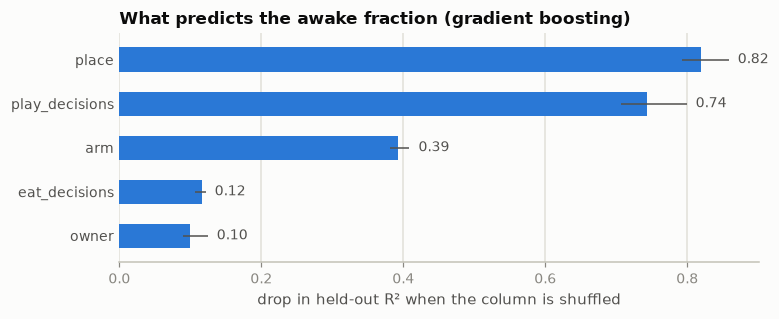

In [18]:
#| label: fig-importance
#| fig-cap: "Exploratory, after the result. Permutation importance (drop in held-out R²) for the better model; bars are the mean over 5 folds, the thin line spans the fold minimum to maximum."
#| code-summary: "Importance chart"
#| fig-alt: "Horizontal bar chart of permutation importance (drop in held-out R²) for the gradient boosting model: place (0.82) and play decisions (0.74) are the largest, the arm comes third (0.39), well ahead of eat decisions and owner type."
m = imp[best][order.index]
fig, ax = plt.subplots(figsize=(7.2, 3.0))
yy = np.arange(len(order))
ax.barh(yy, m.mean(), height=0.55, color=style.ACCENT, zorder=3)
ax.hlines(yy, m.min(), m.max(), color=style.INK_2, lw=1, zorder=4)
for k, v in enumerate(m.mean()):
    ax.annotate(f"{v:.2f}", (m.max().iloc[k], k), xytext=(6, 0), textcoords="offset points",
                va="center", color=style.INK_2, fontsize=9)
ax.set_yticks(yy, order.index)
ax.set_ylim(len(order) - 0.4, -0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("drop in held-out R² when the column is shuffled")
ax.set_title(f"What predicts the awake fraction ({best})")
fig.tight_layout()
plt.show()

**How to read it.** Where the food is and how often the pet chose to play explain the most variation between lives; the arm comes third, well ahead of eat decisions and owner type. The arm's importance is not small, but it is not a measure of the effect's size either: an R² drop says how reliably a column separates lives, and the paired design already showed that the arm difference is very consistent (large dz) while being only about 16 minutes a day. Play decisions are themselves partly a consequence of the arm, so the two share some of the same information. A high R² here says the simulation is fairly predictable from these columns. It does **not** say that changing any of them would cause the change, and it does not replace the pre-registered reading.

In [19]:
#| label: model-baseline
#| code-summary: "Baseline R² (DummyRegressor, same folds) and partial dependence"
from sklearn.dummy import DummyRegressor
from sklearn.inspection import partial_dependence

base = [r2_score(y[test], DummyRegressor().fit(X.iloc[train], y[train]).predict(X.iloc[test]))
        for train, test in GroupKFold(n_splits=5).split(X, y, groups)]
Xf = X.astype({c: float for c in NUM})  # partial_dependence refuses integer columns
gb = models["gradient boosting"]().fit(Xf, y)  # one fit on all lives, only to describe the model
top2 = list(order.index[:2])
assert top2 == ["place", "play_decisions"]
pdp_place = partial_dependence(gb, Xf, ["place"], categorical_features=CAT, kind="average")
pdp_play = partial_dependence(gb, Xf, ["play_decisions"], kind="average", grid_resolution=50)
place_pd = pd.Series(pdp_place["average"][0], index=pdp_place["grid_values"][0])
play_grid, play_pd = pdp_play["grid_values"][0], pdp_play["average"][0]
assert abs(np.mean(base)) < 0.01 and cv.loc["gradient boosting", "mean_R2"] > np.mean(base) + 0.5
assert place_pd.idxmax() == "far" and play_pd[-1] > play_pd[0]
alt = {"at_feeder": 0.515, "far": 0.533, "near": 0.512, "play_first": 0.507, "play_last": 0.528}  # the figure's alt text
got = {**place_pd.to_dict(), "play_first": play_pd[0], "play_last": play_pd[-1]}
assert all(abs(got[k] - v) < 0.0015 for k, v in alt.items()) and (play_grid[0], play_grid[-1]) == (28, 108)
say(f"""**Exploratory, after the result.** A baseline that always predicts the training mean
(`DummyRegressor`, the same 5 `GroupKFold` folds) scores held-out R² **{np.mean(base):.4f} ± {np.std(base, ddof=1):.4f}**:
that is what "no information" looks like, so the models' R² above is all gained from the columns.

**Partial dependence** of the gradient-boosting model, fitted once on all {len(X):,} lives: set one column to a
value for every life, keep the others as they are, and average the predictions. For `place` the average predicted
awake fraction is {", ".join(f"{p} {place_pd[p]:.3f}" for p in cs.PLACES)}; for `play_decisions` it rises from
{play_pd[0]:.3f} to {play_pd[-1]:.3f} between {play_grid[0]:.0f} and {play_grid[-1]:.0f} play decisions per life
(the 5th to 95th percentile).""")

**Exploratory, after the result.** A baseline that always predicts the training mean
(`DummyRegressor`, the same 5 `GroupKFold` folds) scores held-out R² **-0.0003 ± 0.0005**:
that is what "no information" looks like, so the models' R² above is all gained from the columns.

**Partial dependence** of the gradient-boosting model, fitted once on all 9,600 lives: set one column to a
value for every life, keep the others as they are, and average the predictions. For `place` the average predicted
awake fraction is at_feeder 0.515, near 0.512, far 0.533; for `play_decisions` it rises from
0.507 to 0.528 between 28 and 108 play decisions per life
(the 5th to 95th percentile).

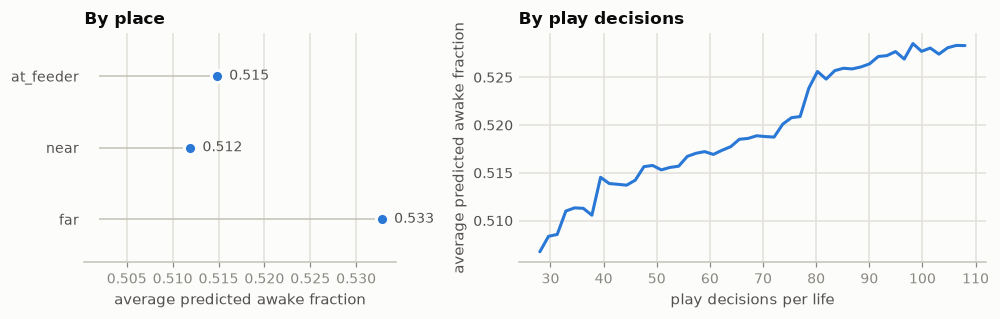

In [20]:
#| label: fig-pdp
#| fig-cap: "Exploratory, after the result. Partial dependence of the gradient-boosting model for its two most important columns: the average predicted awake fraction when every life is given that place (left) or that number of play decisions (right, 5th to 95th percentile). A description of the fitted model, not of what changing a column would cause."
#| code-summary: "Partial dependence chart"
#| fig-alt: "Two-panel partial dependence chart of the gradient boosting model. Left: average predicted awake fraction by place: far 0.533, at_feeder 0.515, near 0.512. Right: average predicted awake fraction against play decisions per life, rising unevenly from about 0.507 at 28 play decisions to about 0.528 at 108."
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.0), gridspec_kw={"width_ratios": [2, 3]})
places = [p for p in cs.PLACES if p in place_pd.index]
yy = np.arange(len(places))
axes[0].hlines(yy, place_pd.min() - 0.01, place_pd.loc[places], color=style.BASELINE, lw=1, zorder=2)
axes[0].plot(place_pd.loc[places], yy, "o", ms=8, color=style.ACCENT, mec=style.SURFACE, mew=2, zorder=3)
for k, p in enumerate(places):
    axes[0].annotate(f"{place_pd[p]:.3f}", (place_pd[p], k), xytext=(8, 0), textcoords="offset points",
                     va="center", color=style.INK_2, fontsize=9)
axes[0].set_yticks(yy, places)
axes[0].set_ylim(len(places) - 0.4, -0.6)
axes[0].grid(axis="y", visible=False)
axes[0].set_xlabel("average predicted awake fraction")
axes[0].set_title("By place")
axes[1].plot(play_grid, play_pd, color=style.ACCENT)
axes[1].grid(axis="y", visible=True)
axes[1].set_xlabel("play decisions per life")
axes[1].set_ylabel("average predicted awake fraction")
axes[1].set_title("By play decisions")
fig.tight_layout()
plt.show()

**How to read the partial dependence.** It describes how the fitted model uses a column, averaged over the other columns *as they occur*: play decisions depend on the arm and on the place, so setting them for every life creates combinations that never happen. It is not an effect of play or of place, and, like the rest of this section, it does not touch the pre-registered reading.

### (c) The reading rule, seen as an equivalence test

**Exploratory, after the result.** L-AWAKE compares D1's 95% interval with the band ±δ_A. Asking whether a 95% interval lies inside ±δ is the same as running **two one-sided tests** (TOST), each at α = 0.025: one tests "the effect is at or below −δ", the other "at or above +δ"; when both are rejected, the interval is inside the band. TOST is the standard way to show that an effect is *smaller than a chosen size*, not only that it differs from zero. It is shown here to make the logic of the rule visible; it is not part of the plan and gives no new label.

In [21]:
#| label: tost
#| code-summary: "TOST on D1 (awake fraction), by hand and with statsmodels"
from statsmodels.stats.weightstats import ttost_paired

from casestudy import explore

d1 = cs.paired_differences(cs.CONTRASTS["D1"]["a"], cs.CONTRASTS["D1"]["b"], "awake_frac_d1_14")
tost = explore.tost_paired(d1, cs.DELTA_A)
p_sm, (_, p_low_sm, _), (_, p_high_sm, _) = ttost_paired(d1, np.zeros_like(d1), -cs.DELTA_A, cs.DELTA_A)
assert abs(np.log10(tost["p_low"]) - np.log10(p_low_sm)) < 1e-6 and abs(np.log10(tost["p_high"]) - np.log10(p_high_sm)) < 1e-6
assert tost["p"] < 0.025 and within  # both one-sided tests reject <=> the 95% CI is inside ±δ_A
assert l_awake == REF["readings"]["L-AWAKE"]["label"]  # the official label is unchanged
say(f"""**Exploratory, after the result.** For D1 on the awake fraction ({cs.fmt(a)}, δ_A = {cs.DELTA_A}):
"effect ≤ −δ_A" is rejected with t = {tost['t_low']:.1f}, p = {tost['p_low']:.1e}; "effect ≥ +δ_A" with
t = {tost['t_high']:.1f}, p = {tost['p_high']:.1e} (199 degrees of freedom; `statsmodels` `ttost_paired` gives the same).

The official rule is **ordered**: its first line, "upper limit < 0", applies and wins, so the official label is and
stays **"{l_awake}"**. The equivalence view makes visible what the order hides: the interval is also inside ±δ_A,
so the effect is **negative and also smaller than the margin**. Both statements hold at once.""")

**Exploratory, after the result.** For D1 on the awake fraction (-0.0109 [-0.0113; -0.0105], δ_A = 0.02):
"effect ≤ −δ_A" is rejected with t = 43.6, p = 5.0e-104; "effect ≥ +δ_A" with
t = -148.1, p = 7.3e-206 (199 degrees of freedom; `statsmodels` `ttost_paired` gives the same).

The official rule is **ordered**: its first line, "upper limit < 0", applies and wins, so the official label is and
stays **"no: with the reward the pet sleeps more"**. The equivalence view makes visible what the order hides: the interval is also inside ±δ_A,
so the effect is **negative and also smaller than the margin**. Both statements hold at once.

In [22]:
#| label: tost-delta
#| code-summary: "How the equivalence part depends on δ"
deltas = [0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02, 0.025, 0.03]
sens = pd.DataFrame([dict(delta=dl, minutes_per_day=f"{cs.minutes(dl):.0f}",
                          tost_p=(lambda p: f"{p:.3f}" if p >= 0.001 else f"{p:.1e}")(explore.tost_paired(d1, dl)["p"]),
                          ci_inside_band="yes" if -dl <= a["ci_low"] and a["ci_high"] <= dl else "no",
                          L_AWAKE_with_this_delta=cs.read_awake(a["ci_low"], a["ci_high"], dl)) for dl in deltas])
show(sens)
d_min = explore.smallest_margin(a["ci_low"], a["ci_high"])
assert sens.L_AWAKE_with_this_delta.nunique() == 1 and sens.L_AWAKE_with_this_delta[0] == l_awake
assert (sens.ci_inside_band == "yes").tolist() == [dl >= d_min for dl in deltas]
assert round(d_min, 4) == 0.0113  # the figure's alt text
say(f"""**Exploratory, after the result.** δ_A = {cs.DELTA_A} has **no external source**. The interval fits inside
±δ for any δ of at least **{d_min:.4f}** (about {cs.minutes(d_min):.0f} minutes a day); below that, the equivalence
part would fail. The label in the last column does not move: the first line of the rule does not use δ at all.
What δ decides here is only whether "smaller than the margin" can also be said.""")

delta,minutes_per_day,tost_p,ci_inside_band,L_AWAKE_with_this_delta
0.0050,7,1.000,no,no: with the reward the pet sleeps more
0.0075,11,1.000,no,no: with the reward the pet sleeps more
0.0100,14,1.000,no,no: with the reward the pet sleeps more
0.0125,18,4.6e-13,yes,no: with the reward the pet sleeps more
0.0150,22,1.1e-48,yes,no: with the reward the pet sleeps more
0.0200,29,5.0e-104,yes,no: with the reward the pet sleeps more
0.0250,36,1.9e-139,yes,no: with the reward the pet sleeps more
0.0300,43,7.4e-165,yes,no: with the reward the pet sleeps more


**Exploratory, after the result.** δ_A = 0.02 has **no external source**. The interval fits inside
±δ for any δ of at least **0.0113** (about 16 minutes a day); below that, the equivalence
part would fail. The label in the last column does not move: the first line of the rule does not use δ at all.
What δ decides here is only whether "smaller than the margin" can also be said.

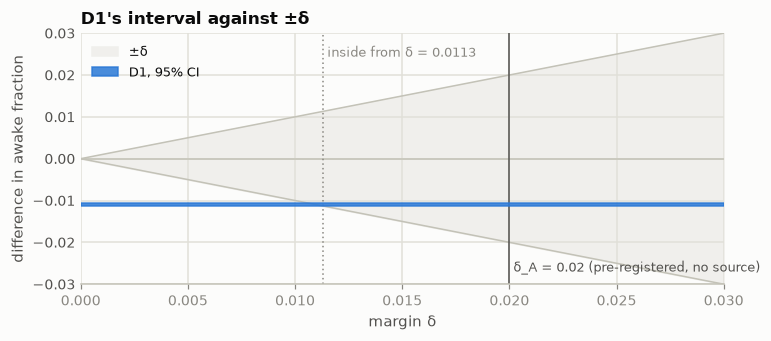

In [23]:
#| label: fig-tost-delta
#| fig-cap: "Exploratory, after the result. D1 on the awake fraction (its 95% interval, the thin blue band near −0.011) against the band ±δ for every δ from 0 to 0.03. The interval is inside the band to the right of the dotted line; the pre-registered δ_A = 0.02 (no external source) is marked."
#| code-summary: "Chart: D1 against ±δ"
#| fig-alt: "Chart with δ on the horizontal axis from 0 to 0.03 and the difference in awake fraction on the vertical axis. A gray funnel shows the band from −δ to +δ. D1's 95% interval is a thin horizontal blue band at about −0.011. It leaves the funnel for δ below about 0.0113 and is inside it from there on, including at the pre-registered δ_A = 0.02."
grid = np.linspace(0, 0.03, 301)
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.fill_between(grid, -grid, grid, color=style.WASH, zorder=0, label="±δ")
ax.plot(grid, grid, color=style.BASELINE, lw=1)
ax.plot(grid, -grid, color=style.BASELINE, lw=1)
ax.axhspan(a["ci_low"], a["ci_high"], color=style.ACCENT, alpha=0.85, zorder=3, label="D1, 95% CI")
ax.axhline(0, color=style.BASELINE, lw=1, zorder=1)
ax.axvline(d_min, color=style.MUTED, lw=1, ls=(0, (1, 2)))
ax.axvline(cs.DELTA_A, color=style.INK_2, lw=1)
ax.text(d_min, 0.027, f" inside from δ = {d_min:.4f}", color=style.MUTED, fontsize=8.5, va="top")
ax.text(cs.DELTA_A, -0.027, f" δ_A = {cs.DELTA_A} (pre-registered, no source)", color=style.INK_2, fontsize=8.5)
ax.set_xlim(0, 0.03)
ax.set_ylim(-0.03, 0.03)
ax.grid(axis="y", visible=True)
ax.set_xlabel("margin δ")
ax.set_ylabel("difference in awake fraction")
ax.set_title("D1's interval against ±δ")
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

### (d) How robust are the intervals?

**Exploratory, after the result.** The official intervals assume that the mean of the 200 unit differences follows a Student t distribution. Two checks that lean on other assumptions:

- a **paired bootstrap**: resample the 200 units with replacement 10,000 times (BCa interval, fixed seed), so the interval comes from the data's own spread instead of the t distribution;
- a **mixed model** on the 4,800 lives of D1 (two arms × 12 cells × 200 units): awake fraction ~ arm + the 12 owner × place cells as fixed effects, with a random intercept per unit (`statsmodels` `MixedLM`, REML).

In [24]:
#| label: bootstrap
#| code-summary: "Paired bootstrap (BCa, 10,000 resamples) next to the t intervals"
SEED = 20261126
boot = []
for (m, cid), r in res.items():
    c = cs.CONTRASTS[cid]
    lo_b, hi_b = explore.bootstrap_ci(cs.paired_differences(c["a"], c["b"], m), seed=SEED)
    boot.append(dict(measure=m, contrast=cid, t_ci=f"[{r['ci_low']:+.4f}; {r['ci_high']:+.4f}]",
                     bootstrap_ci=f"[{lo_b:+.4f}; {hi_b:+.4f}]", gap=max(abs(lo_b - r["ci_low"]), abs(hi_b - r["ci_high"])),
                     same_side_of_0="yes" if (np.sign(lo_b), np.sign(hi_b)) == (np.sign(r["ci_low"]), np.sign(r["ci_high"])) else "no"))
boot = pd.DataFrame(boot)
show(boot.assign(gap=boot.gap.map("{:.5f}".format)))
assert (boot.same_side_of_0 == "yes").all() and boot.gap.max() < 2e-4
b_awake = boot[(boot.measure == "awake_frac_d1_14") & (boot.contrast == "D1")].iloc[0]
say(f"""**Exploratory, after the result.** The bootstrap and t intervals agree to about the fourth decimal: the largest
gap at any endpoint is **{boot.gap.max():.5f}**, and no interval changes side of zero. With 200 units, each already an
average over 12 cells, the mean is close to normal, so the t interval has little to get wrong.""")

measure,contrast,t_ci,bootstrap_ci,gap,same_side_of_0
awake_frac_d1_14,D1,[-0.0113; -0.0105],[-0.0113; -0.0105],0.00001,yes
awake_frac_d1_14,D2,[+0.0093; +0.0100],[+0.0093; +0.0100],0.00000,yes
awake_frac_d1_14,D3,[+0.0067; +0.0073],[+0.0067; +0.0073],0.00001,yes
time_well,D1,[+0.0152; +0.0215],[+0.0151; +0.0214],0.00011,yes
time_well,D2,[-0.0007; +0.0056],[-0.0006; +0.0056],0.00004,yes
time_well,D3,[-0.0015; +0.0038],[-0.0014; +0.0039],0.00007,yes


**Exploratory, after the result.** The bootstrap and t intervals agree to about the fourth decimal: the largest
gap at any endpoint is **0.00011**, and no interval changes side of zero. With 200 units, each already an
average over 12 cells, the mean is close to normal, so the t interval has little to get wrong.

In [25]:
#| label: mixed-model
#| code-summary: "Mixed model for D1 on the awake fraction (statsmodels MixedLM)"
import warnings

import statsmodels.formula.api as smf

two = cs.sql(f"SELECT unit, owner, place, arm, awake_frac_d1_14 FROM lives "
             f"WHERE arm IN ('{cs.CONTRASTS['D1']['a']}', '{cs.CONTRASTS['D1']['b']}') ORDER BY arm, owner, place, unit")
two["credit"] = (two.arm == cs.CONTRASTS["D1"]["a"]).astype(float)
two["cell"] = two.owner + "|" + two.place
with warnings.catch_warnings(record=True) as warned:  # see the note on the boundary warning below
    warnings.simplefilter("always")
    mm = smf.mixedlm("awake_frac_d1_14 ~ credit + C(cell)", two, groups=two["unit"]).fit(reml=True)
    mm_check = smf.mixedlm("awake_frac_d1_14 ~ credit + C(cell)", two, groups=two["unit"]).fit(reml=True, method="powell")
var_unit, var_res = float(mm.cov_re.iloc[0, 0]), float(mm.scale)
assert mm.converged and var_unit > 0 and abs(mm_check.bse["credit"] / mm.bse["credit"] - 1) < 1e-4
# the same model with the arm effect allowed to differ by cell, averaged over the 12 cells
with warnings.catch_warnings(record=True) as warned_i:
    warnings.simplefilter("always")
    mi = smf.mixedlm("awake_frac_d1_14 ~ C(cell) * credit", two, groups=two["unit"]).fit(reml=True)
names = list(mi.fe_params.index)
L = np.array([[1.0 if n == "credit" else 1 / 12 if n.endswith(":credit") else 0.0 for n in names]])
avg = mi.t_test(L)
z = 1.959963984540054
rows_mm = [("paired t over units (official)", a["mean"], a["sd"] / np.sqrt(cs.N_UNITS), a["ci_low"], a["ci_high"]),
           ("mixed model: arm + cells, random intercept per unit", mm.params["credit"], mm.bse["credit"],
            *mm.conf_int().loc["credit"]),
           ("mixed model with arm × cell, averaged over cells", float(avg.effect[0]), float(avg.sd[0, 0]),
            float(avg.effect[0]) - z * float(avg.sd[0, 0]), float(avg.effect[0]) + z * float(avg.sd[0, 0]))]
mmt = pd.DataFrame(rows_mm, columns=["method", "estimate", "std_error", "ci_low", "ci_high"])
show(mmt.round({"estimate": 5, "std_error": 6, "ci_low": 5, "ci_high": 5}))
se_t, se_mm, se_mi = mmt.std_error
boundary = ('`statsmodels` warns that this fit "may be on the boundary of the parameter space". '
            if any("boundary" in str(x.message) for x in warned) else "")
assert (mmt.estimate - a["mean"]).abs().max() < 1e-9  # balanced design: the same estimate
assert mmt.ci_high.max() < 0 and se_mm > 1.1 * se_t and abs(se_mi / se_t - 1) < 0.05
say(f"""**Exploratory, after the result.** The mixed model gives the same estimate ({mm.params['credit']:+.5f}: with every
unit in every cell and both arms, its arm coefficient is the mean of the paired differences) and a
**{se_mm / se_t - 1:.0%} wider** interval, {cs.fmt(dict(mean=mmt.estimate[1], ci_low=mmt.ci_low[1], ci_high=mmt.ci_high[1]), 5)},
still entirely below zero. They differ because the model has one arm coefficient for all 12 cells: how much the
arm moves the awake fraction differs from cell to cell, and the model counts those differences as noise, whereas
the paired t first averages each unit over its 12 cells, so they cancel. Letting the arm effect differ by cell and
averaging it over the cells brings the standard error to {se_mi:.6f}, against {se_t:.6f} for the paired t.

{boundary}The variance between units is small ({var_unit:.1e}, against {var_res:.1e} within units) but not zero, and a
second optimizer (Powell) gives the same standard error to four significant digits.""")

method,estimate,std_error,ci_low,ci_high
paired t over units (official),-0.01091,0.000209,-0.01132,-0.01049
"mixed model: arm + cells, random intercept per unit",-0.01091,0.000248,-0.01139,-0.01042
"mixed model with arm × cell, averaged over cells",-0.01091,0.000211,-0.01132,-0.01049


**Exploratory, after the result.** The mixed model gives the same estimate (-0.01091: with every
unit in every cell and both arms, its arm coefficient is the mean of the paired differences) and a
**19% wider** interval, -0.01091 [-0.01139; -0.01042],
still entirely below zero. They differ because the model has one arm coefficient for all 12 cells: how much the
arm moves the awake fraction differs from cell to cell, and the model counts those differences as noise, whereas
the paired t first averages each unit over its 12 cells, so they cancel. Letting the arm effect differ by cell and
averaging it over the cells brings the standard error to 0.000211, against 0.000209 for the paired t.

`statsmodels` warns that this fit "may be on the boundary of the parameter space". The variance between units is small (5.4e-06, against 7.4e-05 within units) but not zero, and a
second optimizer (Powell) gives the same standard error to four significant digits.

## 9. What this does not show, and what I would do differently

**What this does not show.**

- Nothing about real players: the simulated owner rewards every time, and immediately.
- Only one reward dose, and no other kinds of reward.
- Only 14 days and these 12 cells.
- Nothing about health: the guard was not measured.
- Not that the reward credit improves welfare: the time-well gain is shared by all three petting arms.
- The separation between credit and body effect is not perfect: the arms diverge after the first petting, and with owners that pet on their own, the credit also reaches the owner's own petting.
- δ_A, the welfare margin and the premise floors have no external source, and were written after the 20-unit look at test seeds.

After the result, the recommendation recorded was not to pursue this reward (at this dose) as the way to a more awake pet; another dose or reward would be a new question with its own plan.

**What I would do differently.**

1. **Test the analysis in the smoke run**, not only the simulation: run the full pipeline end to end on a handful of lives, so a missing field fails in minutes, not at the end of the whole run.
2. **Write the "why" rule for both signs.** L-WHY assumed D1 would move in the same direction as D2 and D3. A rule that names its sign assumptions would have produced a label that needs no caveat.
3. **Justify δ_A and the margins with a source** (a measured day-to-day variation, a design target or prior data) instead of a judgement call.
4. **Plan the body-only vs control contrast.** It turned out to be the key to interpreting the result, and here it can only be shown as exploratory.
5. **Report absolute and standardized effects together** from the start, so a large dz is never mistaken for a large effect.

## 10. Reproduce it

Everything on this site is rebuilt from the published data with one command (Python ≥ 3.12 and [uv](https://docs.astral.sh/uv/); all dependencies, including Quarto, are pinned in `uv.lock`):

```
uv sync
uv run python scripts/reproduce.py
```

It runs the DuckDB integrity checks, executes both notebooks in place (each stops on a failed assertion) and renders this site into `docs/`. The [reproduction appendix](01_reproduce_official_results.ipynb) recomputes all 18 official contrast × measure values.

In [26]:
#| label: gate
assert len([c for c in CHECKS if c.startswith(("D1", "D2", "D3"))]) == 6
assert len([c for c in CHECKS if c.startswith(("by_owner", "by_place"))]) == (4 + 3) * 2 * 3
say(f"**Gate:** {len(CHECKS)} official values and labels on this page were recomputed and matched "
    f"`reference.json` (tolerance {cs.TOL:g}).")

**Gate:** 61 official values and labels on this page were recomputed and matched `reference.json` (tolerance 1e-09).

## Appendix: the pre-registration entry

The study's entry in the project's pre-registration file, as committed in `455c6d61` (2026-11-20 14:06:26 UTC−3), before the plan was approved, the code merged and the run started. Only the lines about the question, the primary outcome, the reading rule with its margins and the stopping rule are quoted; the other lines of the entry are not reproduced, and "[…]" marks text left out inside a quoted line. Section numbers refer to the analysis plan, which is not published; its L-WHY and L-WELL rules are the ones in section 3 above.

**Translated excerpt**

| field | value |
|---|---|
| hypothesis | the questions Q-AWAKE, Q-WHY and Q-WELL. "The expected outcome is 'no: sleeps more or stays the same'", from the test seeds (sections 1 and 2.2) |
| primary contrast | D1 = R-CB − R0 on T_AWAKE (the fraction of decisions without sleeping, days 1 to 14), on the mean of the 12 cells per unit, 95% CI by t, n 200; δ_A = 0.02, NO SOURCE. Alongside: D2 = R-CB − R-SORT, D3 = R-CB − R-CORPO and D1 on "Time well", with the margin 0.032 (sections 6 and 7) |
| reading rule | L-AWAKE, in order: D1's upper limit < 0, "no: with the reward the pet sleeps more"; the CI within ±δ_A, "no: stays the same"; the lower limit > δ_A, "yes, stays awake more"; otherwise "inconclusive". L-WHY and L-WELL, in section 7. No measure is a gate |
| stopping rule | runs once; the integrity checks […] fail loudly before any measurement; the premises […] are recorded and do not stop it; with the smoke test's projection above 4 h the run does not go ahead […] (sections 5 and 9) |

**Original (Portuguese)**

| campo | valor |
|---|---|
| hipótese | as perguntas Q-ACORDADO, Q-PORQUÊ e Q-BEM. "O desfecho esperado é 'não: dorme mais ou fica igual'", pelas sementes dos testes (seções 1 e 2.2) |
| contraste primário | D1 = R-CB − R0 no T_ACORDADO (a fração das decisões sem dormir, dias 1 a 14), na média das 12 células por unidade, IC95 pelo t, n 200; δ_A = 0,02, SEM FONTE. Ao lado: D2 = R-CB − R-SORT, D3 = R-CB − R-CORPO e o D1 no "Tempo bem", com a margem 0,032 (seções 6 e 7) |
| regra de leitura | L-ACORDADO, em ordem: o limite de cima do D1 < 0, "não: com a recompensa o pet dorme mais"; o IC dentro de ±δ_A, "não: fica igual"; o limite de baixo > δ_A, "sim, fica mais tempo acordado"; senão "inconclusivo". A L-PORQUÊ e a L-BEM, na seção 7. Nenhuma medida é gate |
| regra de parada | roda uma vez; as conferências […] falham alto antes de qualquer medida; as premissas […] ficam registradas e não param; com a projeção da fumaça acima de 4 h a run não roda […] (seções 5 e 9) |
